# Clasificación de razas de gatos con ResNet18

Modelo final desarrollado para la práctica de Aprendizaje Automático II.

Se utiliza Transfer Learning con una ResNet18 preentrenada sobre ImageNet
y adaptada a un problema de clasificación de 10 razas de gatos.

In [ ]:
import os
import copy
import ssl
import certifi
import time

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
ruta_dataset = "../dataset_cat"


In [7]:
transform_train_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

transform_eval_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [8]:
dataset_train_resnet = ImageFolder(
    root=ruta_dataset,
    transform=transform_train_resnet
)

dataset_eval_resnet = ImageFolder(
    root=ruta_dataset,
    transform=transform_eval_resnet
)

In [11]:
indices = np.arange(len(dataset_eval_resnet))
etiquetas = dataset_eval_resnet.targets

indices_train, indices_temp = train_test_split(
    indices,
    test_size=0.30,
    stratify=etiquetas,
    random_state=42
)

indices_val, indices_test = train_test_split(
    indices_temp,
    test_size=0.50,
    stratify=np.array(etiquetas)[indices_temp],
    random_state=42
)

print("Entrenamiento:", len(indices_train))
print("Validación:", len(indices_val))
print("Test:", len(indices_test))

Entrenamiento: 1129
Validación: 242
Test: 242


In [12]:
train_dataset_resnet = Subset(
    dataset_train_resnet,
    indices_train
)

val_dataset_resnet = Subset(
    dataset_eval_resnet,
    indices_val
)

test_dataset_resnet = Subset(
    dataset_eval_resnet,
    indices_test
)

In [13]:
train_loader_resnet = DataLoader(
    train_dataset_resnet,
    batch_size=32,
    shuffle=True
)

val_loader_resnet = DataLoader(
    val_dataset_resnet,
    batch_size=32,
    shuffle=False
)

test_loader_resnet = DataLoader(
    test_dataset_resnet,
    batch_size=32,
    shuffle=False
)

In [15]:
os.environ["SSL_CERT_FILE"] = certifi.where()

ssl._create_default_https_context = lambda: ssl.create_default_context(
    cafile=certifi.where()
)

In [16]:
weights = ResNet18_Weights.DEFAULT

model = resnet18(weights=weights)

print(model.fc)

Linear(in_features=512, out_features=1000, bias=True)


In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", device)

Dispositivo: cpu


In [18]:
for parametro in model.parameters():
    parametro.requires_grad = False

model.fc = nn.Linear(
    model.fc.in_features,
    10
)

model = model.to(device)

print(model.fc)

Linear(in_features=512, out_features=10, bias=True)


In [19]:
for nombre, parametro in model.named_parameters():

    if parametro.requires_grad:
        print(nombre)

fc.weight
fc.bias


In [20]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

max_epochs = 30
patience = 5
min_delta = 0.001

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0

best_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

In [21]:
for epoch in range(max_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for imagenes, etiquetas in train_loader_resnet:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        optimizer.zero_grad()

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imagenes.size(0)

        predicciones = salidas.argmax(dim=1)

        correct += (predicciones == etiquetas).sum().item()
        total += etiquetas.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total


    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for imagenes, etiquetas in val_loader_resnet:

            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            salidas = model(imagenes)

            loss = criterion(salidas, etiquetas)

            val_running_loss += loss.item() * imagenes.size(0)

            predicciones = salidas.argmax(dim=1)

            val_correct += (predicciones == etiquetas).sum().item()
            val_total += etiquetas.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total


    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    print(
        f"Época {epoch + 1:02d}/{max_epochs} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Val Loss: {val_loss:.4f} - "
        f"Train Accuracy: {train_accuracy:.2f}% - "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )


    if val_loss < best_val_loss - min_delta:

        best_val_loss = val_loss
        best_val_acc = val_accuracy
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(model.state_dict())

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    if epochs_without_improvement >= patience:

        print("Parada temprana")
        break


model.load_state_dict(best_weights)

Época 01/30 - Train Loss: 1.8435 - Val Loss: 1.2716 - Train Accuracy: 39.06% - Val Accuracy: 64.46%
Época 02/30 - Train Loss: 1.0232 - Val Loss: 0.8794 - Train Accuracy: 78.65% - Val Accuracy: 78.10%
Época 03/30 - Train Loss: 0.7398 - Val Loss: 0.6750 - Train Accuracy: 82.29% - Val Accuracy: 86.78%
Época 04/30 - Train Loss: 0.5652 - Val Loss: 0.5773 - Train Accuracy: 88.49% - Val Accuracy: 86.36%
Época 05/30 - Train Loss: 0.4970 - Val Loss: 0.5055 - Train Accuracy: 88.40% - Val Accuracy: 86.36%
Época 06/30 - Train Loss: 0.4506 - Val Loss: 0.4841 - Train Accuracy: 88.40% - Val Accuracy: 85.54%
Época 07/30 - Train Loss: 0.3999 - Val Loss: 0.4641 - Train Accuracy: 90.61% - Val Accuracy: 85.12%
Época 08/30 - Train Loss: 0.3516 - Val Loss: 0.4275 - Train Accuracy: 91.23% - Val Accuracy: 86.78%
Época 09/30 - Train Loss: 0.3511 - Val Loss: 0.4235 - Train Accuracy: 91.23% - Val Accuracy: 85.95%
Época 10/30 - Train Loss: 0.3269 - Val Loss: 0.4066 - Train Accuracy: 90.61% - Val Accuracy: 86.36%


<All keys matched successfully>

In [22]:
elapsed = (time.time() - start_time) / 60

print("\nEntrenamiento terminado")
print("Mejor época:", best_epoch)
print(f"Mejor pérdida de validación: {best_val_loss:.4f}")
print(f"Precisión de validación en esa época: {best_val_acc:.2f}%")
print(f"Tiempo total: {elapsed:.2f} minutos")


Entrenamiento terminado
Mejor época: 17
Mejor pérdida de validación: 0.3404
Precisión de validación en esa época: 88.43%
Tiempo total: 13.60 minutos


In [31]:
results_dir = "../results"

os.makedirs(results_dir, exist_ok=True)

print("Resultados guardados en:", results_dir)

Resultados guardados en: ../results


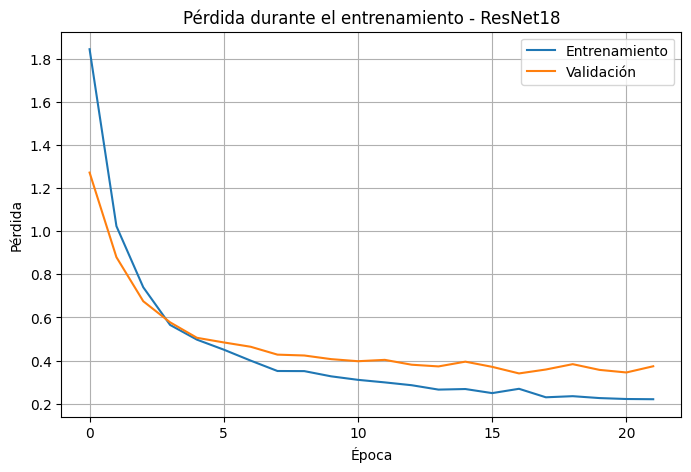

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Entrenamiento")
plt.plot(val_losses, label="Validación")

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida durante el entrenamiento - ResNet18")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(results_dir, "resnet18_loss.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

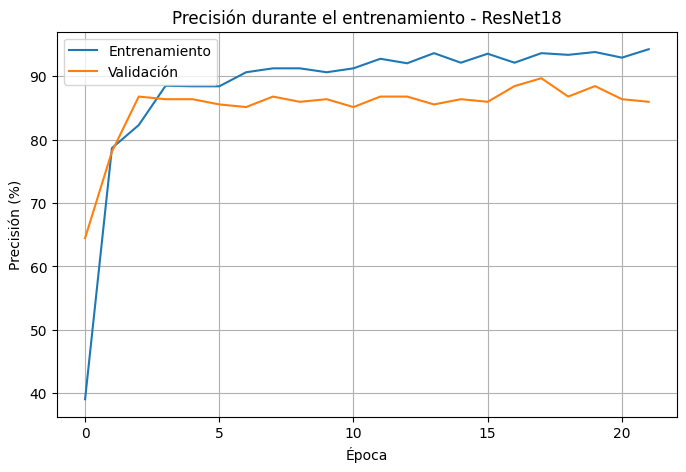

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Entrenamiento")
plt.plot(val_accuracies, label="Validación")

plt.xlabel("Época")
plt.ylabel("Precisión (%)")
plt.title("Precisión durante el entrenamiento - ResNet18")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(results_dir, "resnet18_accuracy.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [34]:
y_true_val = []
y_pred_val = []

model.eval()

with torch.no_grad():

    for imagenes, etiquetas in val_loader_resnet:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        salidas = model(imagenes)
        predicciones = salidas.argmax(dim=1)

        y_true_val.extend(etiquetas.cpu().numpy())
        y_pred_val.extend(predicciones.cpu().numpy())

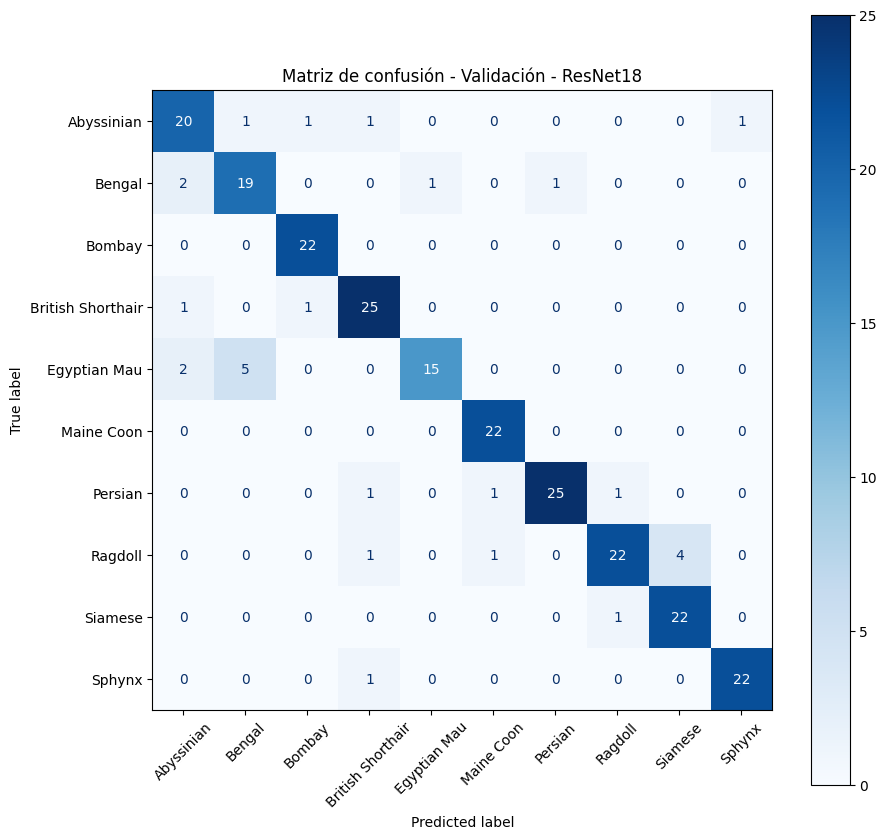

In [35]:
matriz_val = confusion_matrix(
    y_true_val,
    y_pred_val
)

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_val,
    display_labels=dataset_eval_resnet.classes
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("Matriz de confusión - Validación - ResNet18")

plt.savefig(
    os.path.join(results_dir, "resnet18_confusion_validation.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [36]:
model.eval()

test_running_loss = 0.0
test_correct = 0
test_total = 0

y_true_test = []
y_pred_test = []

with torch.no_grad():

    for imagenes, etiquetas in test_loader_resnet:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        salidas = model(imagenes)

        loss = criterion(salidas, etiquetas)

        test_running_loss += loss.item() * imagenes.size(0)

        predicciones = salidas.argmax(dim=1)

        test_correct += (predicciones == etiquetas).sum().item()
        test_total += etiquetas.size(0)

        y_true_test.extend(etiquetas.cpu().numpy())
        y_pred_test.extend(predicciones.cpu().numpy())

test_loss = test_running_loss / test_total
test_accuracy = 100 * test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss: 0.3128
Test Accuracy: 90.50%


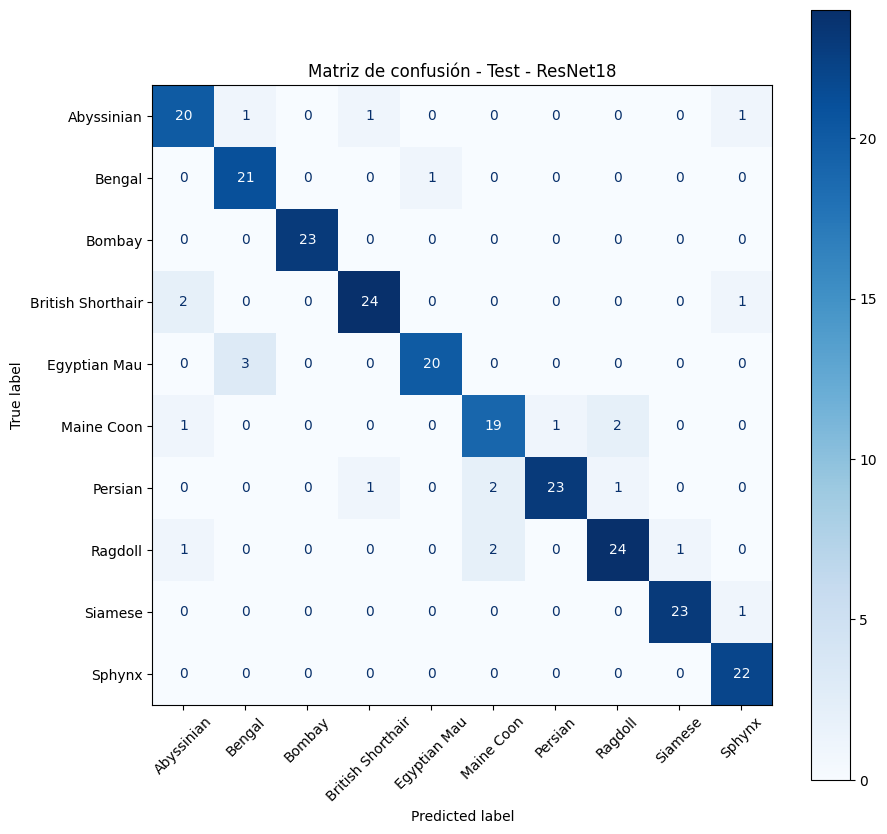

In [37]:
matriz_test = confusion_matrix(
    y_true_test,
    y_pred_test
)

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_test,
    display_labels=dataset_eval_resnet.classes
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("Matriz de confusión - Test - ResNet18")

plt.savefig(
    os.path.join(results_dir, "resnet18_confusion_test.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()